# 2.3 Analyzing the model

## Live code in this page

This page uses **live code**. Click the rocket button (🚀) at the top of this page, above the title, then choose "▶ Live Code". The loading may take some time so it is good to start the Live Code before reading on. The Live Code engine is ready when you see a text under the page's title, stating something like "Launching from mybinder.org: **ready**.

**Note:** Code that you edit in the live code blocks is not saved. Any changes you make to the code blocks is lost once you move on from the page. Therefore, if you want to keep your work, save a copy of it in a local document.

The code block below defines some imports and functions that will be helpful in the current page. It is run automatically when you run the "▶ Live Code" button. You may have a look at it if you like, but that is not neccesary for this course.

In [10]:
"""

"""

import greenlight
import traceback
import ipywidgets as widgets
import matplotlib.pyplot as plt
import copy

from IPython.display import display

%matplotlib widget

slider_names = ["W init", "Iw", "LUE"]
start_values = [75,       50,   4.3  ]
min_values   = [0,        0,    0    ]
max_values   = [250,      250,  20   ]
step_sizes   = [0.1,      1,    0.01 ]

var_names    = ["W",    "Iw",         "LUE"]
var_fields   = ["init", "definition", "definition"]
output = widgets.Output()

sliders = []
# Define the input sliders
for name, start_val, min_val, max_val, step in zip(slider_names, start_values, min_values, max_values, step_sizes):
    sliders.append(
        widgets.FloatSlider(
            value=start_val,
            min=min_val,
            max=max_val,
            step=step,
            description=name,
            continuous_update=False
        )
    )


# Define the buttons
run_button = widgets.Button(
    description='Run model',
    button_style='success',
    icon='play'
)
delete_button = widgets.Button(
    description='Delete latest curve',
    button_style='danger',
    icon='trash'
)

# Function to run the model
def run_model(button):
    print("Run button clicked!")

    try:
        # Read slider values
        s_values = []
        for slider in sliders:
            s_values.append(slider.value)
        
        crop_definition_new = copy.deepcopy(crop_definition)
        
        for val, var, field in zip(s_values, var_names, var_fields):
            crop_definition_new[var][field] = str(val)
            
        # Create a new model
        model = greenlight.GreenLight(input_prompt=crop_definition_new)

        # Run the model
        model.run()

        # Read the output file
        data = model.full_sol

        # Add a new curve
        label = ", ".join([f"{s_name}: {s_val}" for s_name, s_val in zip(slider_names, s_values)])

        # line, = ax.plot(
        #     data.full_sol["Time"]/3600,
        #     data.full_sol["W"],
        #     label=label
        # )

        line, = ax.plot(
            data.iloc[:,0]/3600,
            data.iloc[:,1],
            label=label
        )

        curves.append(line)
        ax.legend()
        fig.canvas.draw_idle()


    except Exception as e:
        traceback.print_exc()


# Function to delete the latest curve
def delete_latest(button):

    if curves:

        # Remove the most recent curve
        line = curves.pop()
        line.remove()

        # Update legend
        ax.legend(loc='best')

        fig.canvas.draw_idle()


# Connect buttons to functions
run_button.on_click(run_model)
delete_button.on_click(delete_latest)




In [2]:
"""
Create a function for displaying dicts in an aesthetic way.
Consider the option of a nested dict (like a GreenLight model definition)
or a "flat" dict (just keys and values)
"""

import pandas as pd

def display_dict(d, dict_type="nested"):
    """
    Below, some dictionaries will be defined in the standard
    GreenLight format for describing models.
    This functions displays such dictionaries in a nicely
    readable format
    """
    if dict_type == "nested":
        df = pd.DataFrame.from_dict(d, orient="index")
        df.index.name = "Variable"
    elif dict_type == "flat":
        df = pd.DataFrame.from_dict(d, orient="index", columns=[""])
    display(df)

In [3]:
"""
Solution to Exercise 6: complete the crop definition dict with description, unit, type, definition, and reference
"""

crop_definition = {
    "W": {
        "description": "Crop dry mass",
        "unit": "g/m2",
        "type": "state",
        "definition": "LUE * ( 1 - exp(-k*LAI) ) * (1/1000000 * Iw)",  # The expression for dW/dT (for states, the definition is the right hand sand of the ODE)
        "init": "75",
        "reference": "Stanghellini (2019), Eq. 2.25. I (MJ/m2/day) is replaced by Iw (W/m2). See also Figure 2.13 there: 75 g/m2 dry mass is a reasonable value for a small crop"
    },
    "LUE": {
        "description": "Light use efficiency",
        "unit": "g crop weight per MJ PAR",
        "type": "const",
        "definition": "4.3",
        "reference": "Stanghellini (2019), Eq. 2.25. See also pg. 49 there: 4.3 is a typical middle value"
    },
    "k": {
        "description": "Light extinction coefficient",
        "unit": "-",
        "type": "const",
        "definition": "0.7",
        "reference": "Stanghellini (2019), Eq. 2.25. See also pg. 39 there: 'For many greenhouse crops, k has a value between 0.6 and 0.8'"
    },
    "LAI": {
        "description": "Leaf area index",
        "unit": "m2 leaf per m2 floor",
        "type": "aux",
        "definition": "W * F_leaves * SLA / 10000",
        "reference": "Stanghellini (2019), Eq. 2.26. "
    },
    "Iw": {
        "description": "Solar PAR radiation",
        "unit": "W PAR per m2",
        "type": "input",
        "definition": "50",
        "reference": "Stanghellini (2019), Eq. 2.25. I (MJ/m2/day) has been replaced by Iw (W/m2). The value of 50 W/m2 is given as an example"
    },
    "F_leaves": {
        "description": "Fraction of crop dry mass partitioned to the leaves",
        "unit": "-",
        "type": "const",
        "definition": "0.8",
        "reference": "Stanghellini (2019), Eq. 2.26. 0.8 is chosen to represent a vegetative crop with mostly leaves"
    },
    "SLA": {
        "description": "Specific leaf area",
        "unit": "cm2/g",
        "type": "const",
        "definition": "250",
        "reference": "Stanghellini (2019), Eq. 2.26. 250 is a middle value for a tomato crop (see Table 2.1, pg. 50 in Stanghellini 2019)"
    }   
 }

# Display the above dict
display_dict(crop_definition)

,description,unit,type,definition,init,reference
Variable,,,,,,
W,Crop dry mass,g/m2,state,LUE * ( 1 - exp(-k*LAI) ) * (1/1000000 * Iw),75,"Stanghellini (2019), Eq. 2.25. I (MJ/m2/day) i..."
LUE,Light use efficiency,g crop weight per MJ PAR,const,4.3,NaN,"Stanghellini (2019), Eq. 2.25. See also pg. 49..."
k,Light extinction coefficient,-,const,0.7,NaN,"Stanghellini (2019), Eq. 2.25. See also pg. 39..."
LAI,Leaf area index,m2 leaf per m2 floor,aux,W * F_leaves * SLA / 10000,NaN,"Stanghellini (2019), Eq. 2.26."
Iw,Solar PAR radiation,W PAR per m2,input,50,NaN,"Stanghellini (2019), Eq. 2.25. I (MJ/m2/day) h..."
F_leaves,Fraction of crop dry mass partitioned to the l...,-,const,0.8,NaN,"Stanghellini (2019), Eq. 2.26. 0.8 is chosen t..."
SLA,Specific leaf area,cm2/g,const,250,NaN,"Stanghellini (2019), Eq. 2.26. 250 is a middle..."


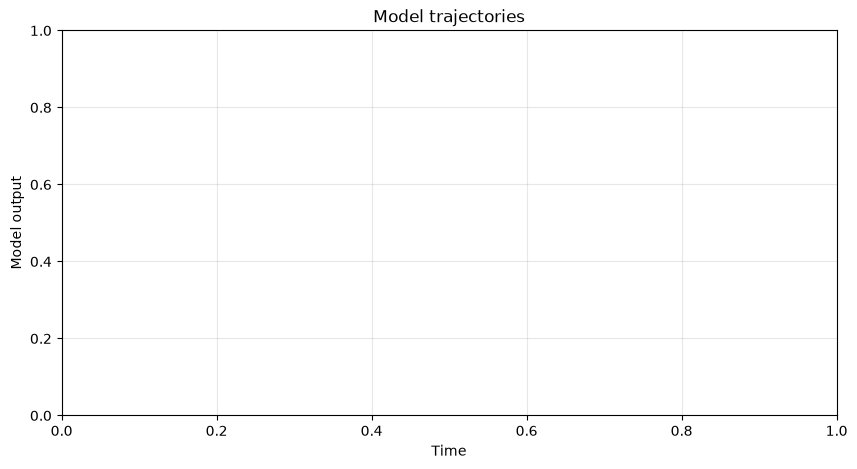

Output()

In [12]:

# --------------------------------------------------
# 3. Set up the plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.set_xlabel('Time')
ax.set_ylabel('Model output')
ax.set_title('Model trajectories')
ax.grid(True, alpha=0.3)

# Store the curves and their labels
curves = []

# Display the interface
controls = widgets.VBox([
    widgets.HTML('<h3>Model parameters</h3>'),
    *sliders,
    widgets.HBox([
        run_button,
        delete_button
    ])
])

display(controls)
display(fig)
display(output)